# Grouping Patients With K-Means Clustering

K-means clustering on two variables from hospital patient data (income and total charges) to see if patients fall into meaningful groups. The number of clusters is checked with an elbow plot and silhouette scores.

The data file isn't included in this repo. See the README for where it goes.

In [1]:
#Import necessary packages
import pandas as pd #load data, evaluate model, dummy variables
import numpy as np #impute nulls
import matplotlib.pyplot as plt #plot visualizations

import seaborn as sns #plot visualizations
sns.set_theme()

import sklearn as sk 
from sklearn.preprocessing import StandardScaler #normalize data using z-score
from sklearn.cluster import KMeans #create k-means object
from sklearn.metrics import silhouette_score #calculate silhouette score (k optimal value)

import warnings #ignore warnings
warnings.filterwarnings('ignore')

In [2]:
# Load the data, keep values of "NONE"
df = pd.read_csv('data/D212_medical_raw.csv', keep_default_na=False)

## Explore and clean the data

In [3]:
#View first 3 rows in full table for overview
df.head(3)

,CaseOrder,Customer_id,Interaction,UID,City,State,County,Zip,Lat,Lng,Population,Area,TimeZone,Job,Children,Age,Income,Marital,Gender,ReAdmis,VitD_levels,Doc_visits,Full_meals_eaten,vitD_supp,Soft_drink,Initial_admin,HighBlood,Stroke,Complication_risk,Overweight,Arthritis,Diabetes,Hyperlipidemia,BackPain,Anxiety,Allergic_rhinitis,Reflux_esophagitis,Asthma,Services,Initial_days,TotalCharge,Additional_charges,Item1,Item2,Item3,Item4,Item5,Item6,Item7,Item8
0,1,C412403,8cd49b13-f45a-4b47-a2bd-173ffa932c2f,3a83ddb66e2ae73798bdf1d705dc0932,Eva,AL,Morgan,35621,34.34960,-86.72508,2951,Suburban,America/Chicago,"Psychologist, sport and exercise",1,53,86575.93,Divorced,Male,No,19.141466,6,0,0,No,Emergency Admission,Yes,No,Medium,No,Yes,Yes,No,Yes,Yes,Yes,No,Yes,Blood Work,10.585770,3726.702860,17939.40342,3,3,2,2,4,3,3,4
1,2,Z919181,d2450b70-0337-4406-bdbb-bc1037f1734c,176354c5eef714957d486009feabf195,Marianna,FL,Jackson,32446,30.84513,-85.22907,11303,Urban,America/Chicago,Community development worker,3,51,46805.99,Married,Female,No,18.940352,4,2,1,No,Emergency Admission,Yes,No,High,Yes,No,No,No,No,No,No,Yes,No,Intravenous,15.129562,4193.190458,17612.99812,3,4,3,4,4,4,3,3
2,3,F995323,a2057123-abf5-4a2c-abad-8ffe33512562,e19a0fa00aeda885b8a436757e889bc9,Sioux Falls,SD,Minnehaha,57110,43.54321,-96.63772,17125,Suburban,America/Chicago,Chief Executive Officer,3,53,14370.14,Widowed,Female,No,18.057507,4,1,0,No,Elective Admission,Yes,No,Medium,Yes,No,Yes,No,No,No,No,No,No,Blood Work,4.772177,2434.234222,17505.19246,2,4,4,4,3,4,3,3


In [4]:
#Get summary of full data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 50 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CaseOrder           10000 non-null  int64  
 1   Customer_id         10000 non-null  str    
 2   Interaction         10000 non-null  str    
 3   UID                 10000 non-null  str    
 4   City                10000 non-null  str    
 5   State               10000 non-null  str    
 6   County              10000 non-null  str    
 7   Zip                 10000 non-null  int64  
 8   Lat                 10000 non-null  float64
 9   Lng                 10000 non-null  float64
 10  Population          10000 non-null  int64  
 11  Area                10000 non-null  str    
 12  TimeZone            10000 non-null  str    
 13  Job                 10000 non-null  str    
 14  Children            10000 non-null  int64  
 15  Age                 10000 non-null  int64  
 16  Income          

In [5]:
#Get summary of my two variables
clusterdata = df[['Income', 'TotalCharge']]
clusterdata.describe().round(2)

,Income,TotalCharge
count,10000.00,10000.00
mean,40490.50,5312.17
std,28521.15,2180.39
min,154.08,1938.31
25%,19598.78,3179.37
50%,33768.42,5213.95
75%,54296.40,7459.70
max,207249.10,9180.73


In [6]:
#Assess for duplicates
clusterdata.duplicated().value_counts()

False    10000
Name: count, dtype: int64

In [7]:
#Assess for nulls
clusterdata.isnull().sum()

Income         0
TotalCharge    0
dtype: int64

<Axes: >

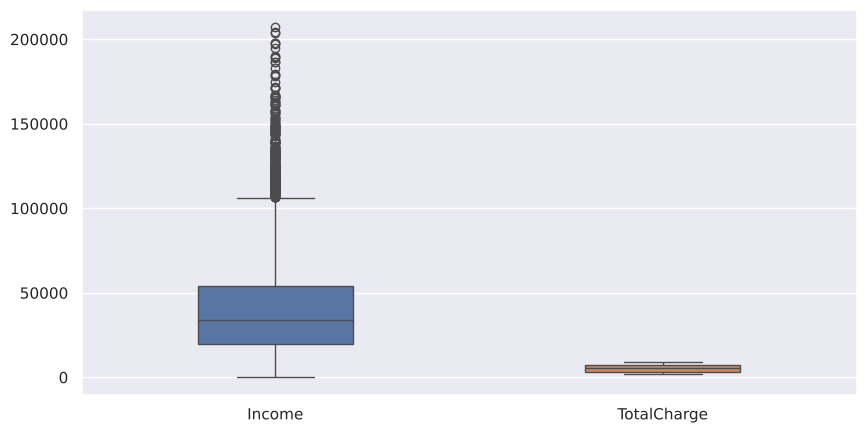

In [8]:
# Create seaborn boxplots of my variables
plt.subplots(figsize=(10, 5))
sns.boxplot(data=clusterdata, width=0.4)

In [9]:
#Check how many patients are in the high-income outlier range
#Keeping these rows: the incomes are valid values, and income is one of my two clustering variables
income_query = clusterdata.query('Income > 110000')
income_query.info()

<class 'pandas.DataFrame'>
Index: 274 entries, 30 to 9955
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Income       274 non-null    float64
 1   TotalCharge  274 non-null    float64
dtypes: float64(2)
memory usage: 6.4 KB


## Scale the data

In [10]:
#Normalize my two variables
scaler = StandardScaler()
scaled_df = scaler.fit_transform(df[['Income', 'TotalCharge']])

In [11]:
scaled_df = pd.DataFrame(scaled_df, columns = ['Income', 'TotalCharge'])
scaled_df

,Income,TotalCharge
0,1.615914,-0.727185
1,0.221443,-0.513228
2,-0.915870,-1.319983
3,-0.026263,-1.460517
4,-1.377325,-1.467285
...,...,...
9995,0.192047,0.705765
9996,-0.894380,1.114312
9997,0.891569,1.359597
9998,-0.378271,1.069727


In [12]:
#Confirm data is scaled, mean = 0 and std = 1
scaled_df.describe().round(2)

,Income,TotalCharge
count,10000.00,10000.00
mean,-0.00,0.00
std,1.00,1.00
min,-1.41,-1.55
25%,-0.73,-0.98
50%,-0.24,-0.05
75%,0.48,0.98
max,5.85,1.77


In [13]:
#Save output to csv file
scaled_df.to_csv('data/medical_clean.csv')

## K-means model

In [14]:
#Build k-means model
k_model = KMeans(n_clusters = 3, n_init = 25, random_state = 300)

k_model.fit(scaled_df)

KMeans(n_clusters=3, n_init=25, random_state=300)

In [15]:
#Evaluate the model
evaluate = pd.Series(k_model.labels_).value_counts()
evaluate

1    4240
0    4219
2    1541
Name: count, dtype: int64

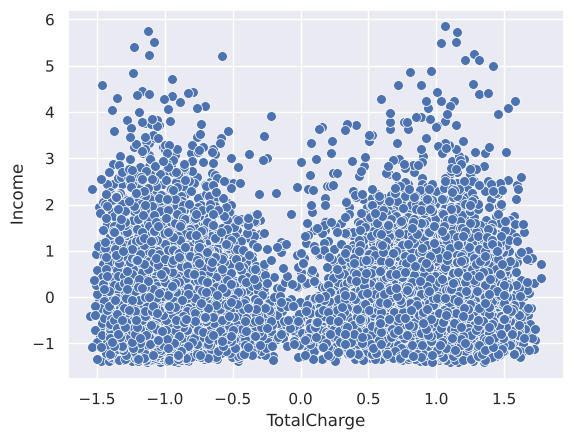

In [16]:
#Visualize the data
ax = sns.scatterplot(data = scaled_df,
                     x = 'TotalCharge',
                     y = 'Income',
                     s = 50)

In [17]:
#Create centroids
centroid = pd.DataFrame(k_model.cluster_centers_,
                        columns = ['Income', 'TotalCharge'])
centroid

,Income,TotalCharge
0,-0.336412,-0.948210
1,-0.323710,0.967738
2,1.807541,-0.068368


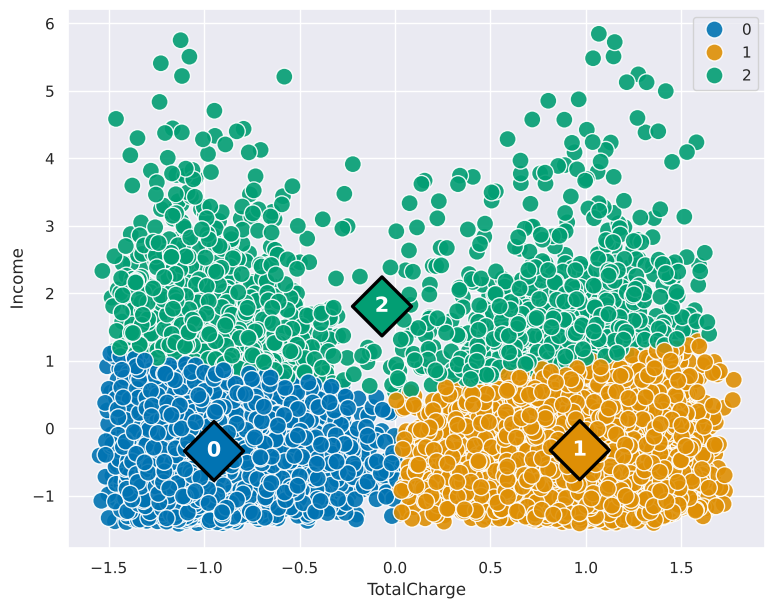

In [18]:
#Visualize centroids and clusters
plt.figure(figsize=(9, 7))

ax = sns.scatterplot(data = scaled_df,
                     x = 'TotalCharge',
                     y = 'Income',
                     hue = k_model.labels_,
                     palette = 'colorblind',
                     alpha = 0.9,
                     s = 150,
                     legend = True)

ax = sns.scatterplot(data = centroid,
                     x = 'TotalCharge',
                     y = 'Income',
                     hue = centroid.index,
                     palette = 'colorblind',
                     s = 900,
                     marker = 'D',
                     edgecolor = 'black',
                     legend = False)

for i in range(len(centroid)):
                plt.text(x = centroid.TotalCharge[i],
                         y = centroid.Income[i],
                         s = i,
                         horizontalalignment = 'center',
                         verticalalignment = 'center',
                         size = 15,
                         weight = 'bold',
                         color = 'white')

## Choosing k

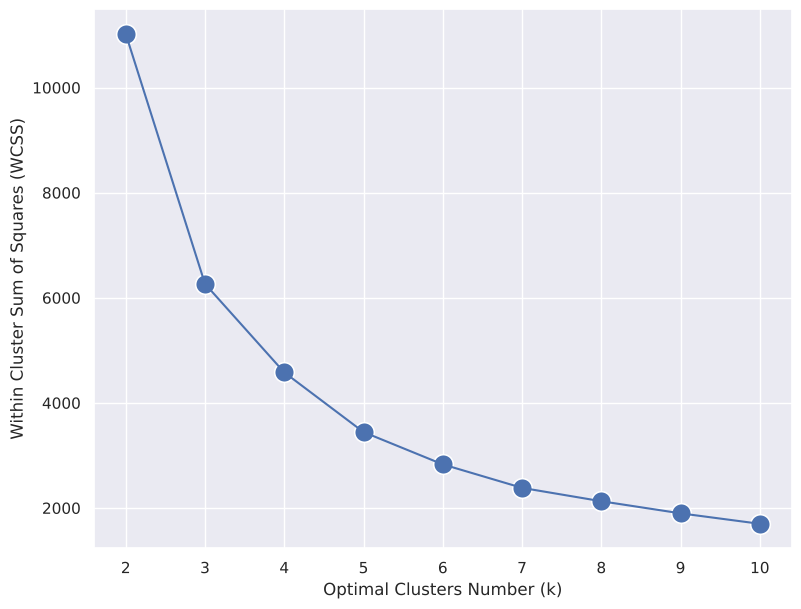

In [19]:
#Use WCSS plot to find k optimal value
wcss = []
for k in range (2, 11):
    model = KMeans(n_clusters = k, n_init = 50, random_state = 300)
    model.fit(scaled_df)
    wcss.append(model.inertia_)
wcss_s = pd.Series(wcss, index = range(2, 11))

plt.figure(figsize=(9, 7))
ax = sns.lineplot(y = wcss_s, x = wcss_s.index)
ax = sns.scatterplot(y = wcss_s, x = wcss_s.index, s = 200)
ax = ax.set(xlabel = 'Optimal Clusters Number (k)',
            ylabel = 'Within Cluster Sum of Squares (WCSS)')

In [20]:
# WCSS plot shows k optimal value is ~ 3-5
# Next, calculate silhouette score
silhouette_sc = silhouette_score(scaled_df, k_model.labels_)
silhouette_sc

0.5220247220647468

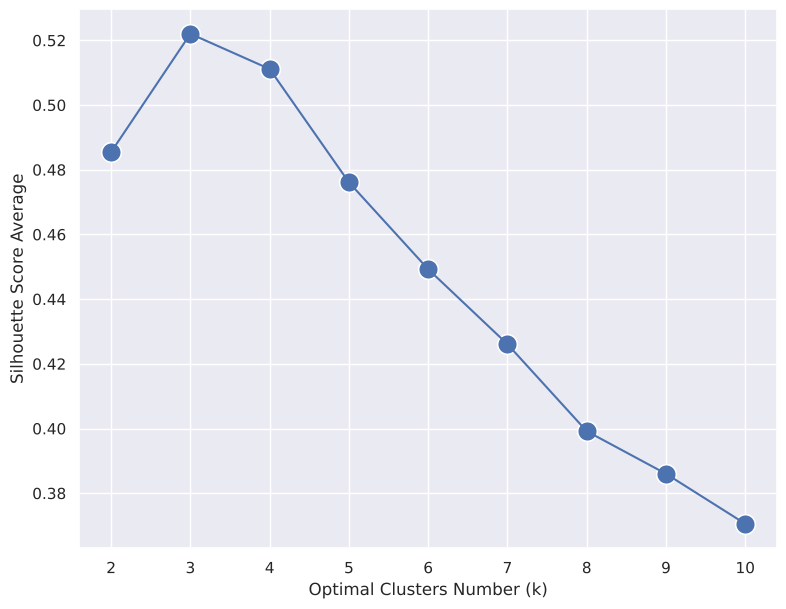

In [21]:
#Silhouette score is closer to 1, meaning data points are similar
#Next, plot silhouette plot to find k optimal value
silhouette = []
for k in range (2, 11):
    model = KMeans(n_clusters = k, n_init = 25, random_state = 300)
    model.fit(scaled_df)
    silhouette.append(silhouette_score(scaled_df, model.labels_))

silhouette_s = pd.Series(silhouette, index = range(2, 11))

plt.figure(figsize=(9, 7))
ax = sns.lineplot(y = silhouette_s, x = silhouette_s.index)
ax = sns.scatterplot(y = silhouette_s, x = silhouette_s.index, s = 200)
ax = ax.set(xlabel = 'Optimal Clusters Number (k)',
            ylabel = 'Silhouette Score Average')

## Cluster profiles

In [22]:
# Silhouette plot shows k optimal value is 3
# Since elbow plot is less clear, I will go with silhouette plot k optimal value for my final model
# Since I used k = 3 for my original model, another model is not needed
# Next, I will label the clusters
df['Cluster'] = k_model.labels_.tolist()
df.head(12)

,CaseOrder,Customer_id,Interaction,UID,City,State,County,Zip,Lat,Lng,Population,Area,TimeZone,Job,Children,Age,Income,Marital,Gender,ReAdmis,VitD_levels,Doc_visits,Full_meals_eaten,vitD_supp,Soft_drink,Initial_admin,HighBlood,Stroke,Complication_risk,Overweight,Arthritis,Diabetes,Hyperlipidemia,BackPain,Anxiety,Allergic_rhinitis,Reflux_esophagitis,Asthma,Services,Initial_days,TotalCharge,Additional_charges,Item1,Item2,Item3,Item4,Item5,Item6,Item7,Item8,Cluster
0,1,C412403,8cd49b13-f45a-4b47-a2bd-173ffa932c2f,3a83ddb66e2ae73798bdf1d705dc0932,Eva,AL,Morgan,35621,34.34960,-86.72508,2951,Suburban,America/Chicago,"Psychologist, sport and exercise",1,53,86575.93,Divorced,Male,No,19.141466,6,0,0,No,Emergency Admission,Yes,No,Medium,No,Yes,Yes,No,Yes,Yes,Yes,No,Yes,Blood Work,10.585770,3726.702860,17939.403420,3,3,2,2,4,3,3,4,2
1,2,Z919181,d2450b70-0337-4406-bdbb-bc1037f1734c,176354c5eef714957d486009feabf195,Marianna,FL,Jackson,32446,30.84513,-85.22907,11303,Urban,America/Chicago,Community development worker,3,51,46805.99,Married,Female,No,18.940352,4,2,1,No,Emergency Admission,Yes,No,High,Yes,No,No,No,No,No,No,Yes,No,Intravenous,15.129562,4193.190458,17612.998120,3,4,3,4,4,4,3,3,0
2,3,F995323,a2057123-abf5-4a2c-abad-8ffe33512562,e19a0fa00aeda885b8a436757e889bc9,Sioux Falls,SD,Minnehaha,57110,43.54321,-96.63772,17125,Suburban,America/Chicago,Chief Executive Officer,3,53,14370.14,Widowed,Female,No,18.057507,4,1,0,No,Elective Admission,Yes,No,Medium,Yes,No,Yes,No,No,No,No,No,No,Blood Work,4.772177,2434.234222,17505.192460,2,4,4,4,3,4,3,3,0
3,4,A879973,1dec528d-eb34-4079-adce-0d7a40e82205,cd17d7b6d152cb6f23957346d11c3f07,New Richland,MN,Waseca,56072,43.89744,-93.51479,2162,Suburban,America/Chicago,Early years teacher,0,78,39741.49,Married,Male,No,16.576858,4,1,0,No,Elective Admission,No,Yes,Medium,No,Yes,No,No,No,No,No,Yes,Yes,Blood Work,1.714879,2127.830423,12993.437350,3,5,5,3,4,5,5,5,0
4,5,C544523,5885f56b-d6da-43a3-8760-83583af94266,d2f0425877b10ed6bb381f3e2579424a,West Point,VA,King William,23181,37.59894,-76.88958,5287,Rural,America/New_York,Health promotion specialist,1,22,1209.56,Widowed,Female,No,17.439069,5,0,2,Yes,Elective Admission,No,No,Low,No,No,No,Yes,No,No,Yes,No,No,CT Scan,1.254807,2113.073274,3716.525786,2,1,3,3,5,3,4,3,0
5,6,S543885,e3b0a319-9e2e-4a23-8752-2fdc736c30f4,03e447146d4a32e1aaf75727c3d1230c,Braggs,OK,Muskogee,74423,35.67302,-95.19180,981,Urban,America/Chicago,Corporate treasurer,3,76,81999.88,Never Married,Male,No,19.612646,6,0,0,No,Observation Admission,No,No,Medium,Yes,Yes,Yes,No,Yes,No,Yes,No,No,Blood Work,5.957250,2636.691180,12742.589910,4,5,4,4,3,5,4,6,2
6,7,E543302,2fccb53e-bd9a-4eaa-a53c-9dfc0cb83f94,e4884a42ba809df6a89ded6c97f460d4,Thompson,OH,Geauga,44086,41.67511,-81.05788,2558,Rural,America/New_York,Hydrologist,0,50,10456.05,Never Married,Male,No,14.751687,6,0,0,No,Emergency Admission,Yes,No,Low,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,No,Intravenous,9.058210,3694.627161,16815.513600,4,3,3,2,3,4,5,5,0
7,8,K477307,ab634508-dd8c-42e5-a4e4-d101a46f2431,5f78b8699d1aa9b950b562073f629ca2,Strasburg,VA,Shenandoah,22641,39.08062,-78.39150,479,Urban,America/New_York,Psychiatric nurse,7,40,38319.29,Divorced,Female,No,19.688673,7,2,0,No,Observation Admission,No,No,Medium,Yes,No,No,No,No,No,No,No,No,Intravenous,14.228019,3021.499039,6930.572138,1,2,2,5,4,2,4,2,0
8,9,Q870521,67b386eb-1d04-4020-9474-542a09d304e3,e8e016144bfbe14974752d834f530e26,Panama City,FL,Bay,32404,30.20097,-85.50610,40029,Urban,America/Chicago,Computer games developer,0,48,55586.48,Widowed,Male,No,19.653320,6,3,0,No,Emergency Admission,No,No,Low,Yes,No,No,Yes,No,No,No,No,No,Intravenous,6.180339,2968.402860,8363.187290,3,3,2,3,3,3,4,2,0
9,10,Z229385,5acd5dd3-f0ae-41c7-9540-cf3e4ecb2e27,687e7ba1b80022c310fa2d4b00db199a,Paynesville,MN,Stearns,56362,45.40325,-94.71424,5840,Urban,America/Chicago,"Production assistant, radio",2,78,38965.22,Never Married,Female,No,18.224324,7,1,2,No,Emergency Admission,Yes,No,High,Yes,No,No,No,No,No,Yes,Yes,Yes,Blood Work

In [23]:
#Create dummy variables for Gender
patients = pd.get_dummies(df, columns = ['Gender'])
patients.head(12)

,CaseOrder,Customer_id,Interaction,UID,City,State,County,Zip,Lat,Lng,Population,Area,TimeZone,Job,Children,Age,Income,Marital,ReAdmis,VitD_levels,Doc_visits,Full_meals_eaten,vitD_supp,Soft_drink,Initial_admin,HighBlood,Stroke,Complication_risk,Overweight,Arthritis,Diabetes,Hyperlipidemia,BackPain,Anxiety,Allergic_rhinitis,Reflux_esophagitis,Asthma,Services,Initial_days,TotalCharge,Additional_charges,Item1,Item2,Item3,Item4,Item5,Item6,Item7,Item8,Cluster,Gender_Female,Gender_Male,Gender_Nonbinary
0,1,C412403,8cd49b13-f45a-4b47-a2bd-173ffa932c2f,3a83ddb66e2ae73798bdf1d705dc0932,Eva,AL,Morgan,35621,34.34960,-86.72508,2951,Suburban,America/Chicago,"Psychologist, sport and exercise",1,53,86575.93,Divorced,No,19.141466,6,0,0,No,Emergency Admission,Yes,No,Medium,No,Yes,Yes,No,Yes,Yes,Yes,No,Yes,Blood Work,10.585770,3726.702860,17939.403420,3,3,2,2,4,3,3,4,2,False,True,False
1,2,Z919181,d2450b70-0337-4406-bdbb-bc1037f1734c,176354c5eef714957d486009feabf195,Marianna,FL,Jackson,32446,30.84513,-85.22907,11303,Urban,America/Chicago,Community development worker,3,51,46805.99,Married,No,18.940352,4,2,1,No,Emergency Admission,Yes,No,High,Yes,No,No,No,No,No,No,Yes,No,Intravenous,15.129562,4193.190458,17612.998120,3,4,3,4,4,4,3,3,0,True,False,False
2,3,F995323,a2057123-abf5-4a2c-abad-8ffe33512562,e19a0fa00aeda885b8a436757e889bc9,Sioux Falls,SD,Minnehaha,57110,43.54321,-96.63772,17125,Suburban,America/Chicago,Chief Executive Officer,3,53,14370.14,Widowed,No,18.057507,4,1,0,No,Elective Admission,Yes,No,Medium,Yes,No,Yes,No,No,No,No,No,No,Blood Work,4.772177,2434.234222,17505.192460,2,4,4,4,3,4,3,3,0,True,False,False
3,4,A879973,1dec528d-eb34-4079-adce-0d7a40e82205,cd17d7b6d152cb6f23957346d11c3f07,New Richland,MN,Waseca,56072,43.89744,-93.51479,2162,Suburban,America/Chicago,Early years teacher,0,78,39741.49,Married,No,16.576858,4,1,0,No,Elective Admission,No,Yes,Medium,No,Yes,No,No,No,No,No,Yes,Yes,Blood Work,1.714879,2127.830423,12993.437350,3,5,5,3,4,5,5,5,0,False,True,False
4,5,C544523,5885f56b-d6da-43a3-8760-83583af94266,d2f0425877b10ed6bb381f3e2579424a,West Point,VA,King William,23181,37.59894,-76.88958,5287,Rural,America/New_York,Health promotion specialist,1,22,1209.56,Widowed,No,17.439069,5,0,2,Yes,Elective Admission,No,No,Low,No,No,No,Yes,No,No,Yes,No,No,CT Scan,1.254807,2113.073274,3716.525786,2,1,3,3,5,3,4,3,0,True,False,False
5,6,S543885,e3b0a319-9e2e-4a23-8752-2fdc736c30f4,03e447146d4a32e1aaf75727c3d1230c,Braggs,OK,Muskogee,74423,35.67302,-95.19180,981,Urban,America/Chicago,Corporate treasurer,3,76,81999.88,Never Married,No,19.612646,6,0,0,No,Observation Admission,No,No,Medium,Yes,Yes,Yes,No,Yes,No,Yes,No,No,Blood Work,5.957250,2636.691180,12742.589910,4,5,4,4,3,5,4,6,2,False,True,False
6,7,E543302,2fccb53e-bd9a-4eaa-a53c-9dfc0cb83f94,e4884a42ba809df6a89ded6c97f460d4,Thompson,OH,Geauga,44086,41.67511,-81.05788,2558,Rural,America/New_York,Hydrologist,0,50,10456.05,Never Married,No,14.751687,6,0,0,No,Emergency Admission,Yes,No,Low,Yes,Yes,Yes,Yes,Yes,Yes,No,Yes,No,Intravenous,9.058210,3694.627161,16815.513600,4,3,3,2,3,4,5,5,0,False,True,False
7,8,K477307,ab634508-dd8c-42e5-a4e4-d101a46f2431,5f78b8699d1aa9b950b562073f629ca2,Strasburg,VA,Shenandoah,22641,39.08062,-78.39150,479,Urban,America/New_York,Psychiatric nurse,7,40,38319.29,Divorced,No,19.688673,7,2,0,No,Observation Admission,No,No,Medium,Yes,No,No,No,No,No,No,No,No,Intravenous,14.228019,3021.499039,6930.572138,1,2,2,5,4,2,4,2,0,True,False,False
8,9,Q870521,67b386eb-1d04-4020-9474-542a09d304e3,e8e016144bfbe14974752d834f530e26,Panama City,FL,Bay,32404,30.20097,-85.50610,40029,Urban,America/Chicago,Computer games developer,0,48,55586.48,Widowed,No,19.653320,6,3,0,No,Emergency Admission,No,No,Low,Yes,No,No,Yes,No,No,No,No,No,Intravenous,6.180339,2968.402860,8363.187290,3,3,2,3,3,3,4,2,0,False,True,False
9,10,Z229385,5acd5dd3-f0ae-41c7-9540-cf3e4ecb2e27,687e7ba1b80022c310fa2d4b00db199a,Paynesville,MN,Stearns,56362,45.40325,-94.71424,5840,Urban,America/Chicago,"Production assistant, r

In [24]:
#Analysis of all patients
patients.agg({
    'Gender_Female' : 'mean',
    'Gender_Male' : 'mean',
    'Age' : 'median',
    'Income' : 'median',
    'TotalCharge' : 'median'}).round(2)

Gender_Female        0.50
Gender_Male          0.48
Age                 53.00
Income           33768.42
TotalCharge       5213.95
dtype: float64

In [25]:
#Analysis of all patients by cluster
patients.groupby('Cluster').agg({
    'Gender_Female' : 'mean',
    'Gender_Male' : 'mean',
    'Age' : 'median',
    'Income' : 'median',
    'TotalCharge' : 'median'})

,Gender_Female,Gender_Male,Age,Income,TotalCharge
Cluster,,,,,
0,0.509836,0.469780,54.0,28691.930,3171.543626
1,0.498349,0.479717,53.0,29177.995,7506.511500
2,0.489293,0.487995,53.0,85141.240,4487.299236
